# Case Type Prediction Model: TF-IDF vs. Fine-Tuned Legal-BERT

This notebook implements a complete Machine Learning pipeline to predict the **Case Type** from legal documents in the **Multi-LexSum** dataset (`case_data.pkl`).

## 1. Background & Methodology
The raw dataset contains **24 distinct case types** with high class imbalance. To build a robust and highly performant classification model, we group these case types into **4 major classes** that are both legally cohesive and statistically balanced:

1. **Employment Discrimination** (derived from `Equal Employment`)
2. **Immigration & Border**
3. **Confinement Conditions** (merging `Prison Conditions` and `Jail Conditions`)
4. **Other Civil Rights** (a combination of all other 20 categories)

### Modeling Strategy:
- **Feature Source**: We use the `summary_long` column, which as **zero nulls**, averages 3,553 characters, and represents a high-quality distillation of the case facts, avoiding the computational overhead of the raw 400,000-character source texts.
- **Feature Representation**: We compare a classical, simple **TF-IDF Baseline** against fine-tuning on a modern embedding model: **Legal-BERT** (`nlpaueb/legal-bert-base-uncased`).
- **Classifiers**: We train and optimize *Multinomial Logistic Regression* and *Linear Support Vector Classifier* across both feature spaces.

In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import warnings

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments

warnings.filterwarnings('ignore')
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load Dataset

In [2]:
print("Loading cleaned case data...")
data_path = 'case_data.pkl'
with open(data_path, 'rb') as f:
    df = pickle.load(f)

df.info()

Loading cleaned case data...
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4539 entries, 0 to 4538
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   4539 non-null   object 
 1   split                4539 non-null   object 
 2   case_name            4539 non-null   object 
 3   case_type            4539 non-null   object 
 4   class_action_sought  4539 non-null   object 
 5   filing_date          4539 non-null   object 
 6   filing_year          4539 non-null   object 
 7   prevailing_party     4539 non-null   object 
 8   n_sources            4539 non-null   int64  
 9   full_text            4539 non-null   object 
 10  total_chars          4539 non-null   int64  
 11  summary_long         4539 non-null   object 
 12  summary_short        3138 non-null   object 
 13  summary_tiny         1603 non-null   object 
 14  cleaned_text         4539 non-null   object 
 15  cleaned_c

## 3. Case Type Grouping & Target Definition

In [3]:
def map_case_type(case_type):
    if not isinstance(case_type, str):
        return 'Other Civil Rights'
    case_type_clean = case_type.strip()
    if case_type_clean == 'Equal Employment':
        return 'Employment Discrimination'
    elif case_type_clean == 'Immigration and/or the Border':
        return 'Immigration & Border'
    elif case_type_clean in ['Prison Conditions', 'Jail Conditions']:
        return 'Confinement Conditions'
    else:
        return 'Other Civil Rights'

df['grouped_case_type'] = df['case_type'].apply(map_case_type)

print("Grouped Case Type Distribution:")
grouped_counts = df['grouped_case_type'].value_counts()
for k, v in grouped_counts.items():
    print(f"   {k}: {v}")

Grouped Case Type Distribution:
   Other Civil Rights: 1710
   Employment Discrimination: 1579
   Confinement Conditions: 727
   Immigration & Border: 523


## 4. Preset Splits Alignment

To ensure zero data leakage and preserve evaluation standard practices, we separate the data exactly using the preset `'split'` column.

In [4]:
train_df = df[df['split'] == 'train'].reset_index(drop=True)
val_df = df[df['split'] == 'validation'].reset_index(drop=True)
test_df = df[df['split'] == 'test'].reset_index(drop=True)

print(f"Train size: {len(train_df)}")
print(f"Validation size: {len(val_df)}")
print(f"Test size: {len(test_df)}")

y_train = train_df['grouped_case_type']
y_val = val_df['grouped_case_type']
y_test = test_df['grouped_case_type']

Train size: 3177
Validation size: 454
Test size: 908


## 5. TF-IDF Baseline Models

Extract TF-IDF unigrams and bigrams, and fit a **Multinomial Logistic Regression** and a **Linear Support Vector Classifier (LinearSVC)**. Comparing them on the validation set to choose the best baseline.

In [5]:
print("Extracting TF-IDF...")
vectorizer = TfidfVectorizer(
    max_features=10000, 
    stop_words='english', 
    ngram_range=(1, 2), 
    sublinear_tf=True
)

X_train_tfidf = vectorizer.fit_transform(train_df['summary_long'])
X_val_tfidf = vectorizer.transform(val_df['summary_long'])
X_test_tfidf = vectorizer.transform(test_df['summary_long'])

print(f"TF-IDF Training Matrix shape: {X_train_tfidf.shape}")

tfidf_models = {
    "Logistic Regression (TF-IDF)": LogisticRegression(max_iter=1000, C=1.0, random_state=42),
    "LinearSVC (TF-IDF)": LinearSVC(max_iter=2000, C=0.5, random_state=42)
}

best_tfidf_val_f1 = -1.0
best_tfidf_name = None
best_tfidf_model = None

for name, model in tfidf_models.items():
    print(f"\n=== Fitting Model: {name} ===")
    model.fit(X_train_tfidf, y_train)
    y_val_pred = model.predict(X_val_tfidf)
    acc = accuracy_score(y_val, y_val_pred)
    f1 = f1_score(y_val, y_val_pred, average='macro')
    print(f"   Validation Accuracy: {acc:.4f}")
    print(f"   Validation Macro F1-Score: {f1:.4f}")
    
    if f1 > best_tfidf_val_f1:
        best_tfidf_val_f1 = f1
        best_tfidf_name = name
        best_tfidf_model = model

print(f"\nBest TF-IDF Model: {best_tfidf_name} (F1: {best_tfidf_val_f1:.4f})")

Extracting TF-IDF...
TF-IDF Training Matrix shape: (3177, 10000)

=== Fitting Model: Logistic Regression (TF-IDF) ===
   Validation Accuracy: 0.9339
   Validation Macro F1-Score: 0.9112

=== Fitting Model: LinearSVC (TF-IDF) ===
   Validation Accuracy: 0.9581
   Validation Macro F1-Score: 0.9449

Best TF-IDF Model: LinearSVC (TF-IDF) (F1: 0.9449)


## 6. Fine-Tuning Domain-Specific Legal-BERT

To leverage domain-specific representation, we perform fine-tuning of **Legal-BERT** (`nlpaueb/legal-bert-base-uncased`).

In [12]:
print("Loading Legal-BERT Tokenizer...")
legal_tokenizer = AutoTokenizer.from_pretrained("nlpaueb/legal-bert-base-uncased")

# Convert labels to integers
label_map = {
    'Employment Discrimination': 0,
    'Immigration & Border': 1,
    'Confinement Conditions': 2,
    'Other Civil Rights': 3
}
train_df['label'] = train_df['grouped_case_type'].map(label_map)
val_df['label'] = val_df['grouped_case_type'].map(label_map)
test_df['label'] = test_df['grouped_case_type'].map(label_map)

class LegalDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels):
        self.encodings = legal_tokenizer(texts, truncation=True, padding=True, max_length=512)
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = LegalDataset(train_df['summary_long'].tolist(), train_df['label'].tolist())
val_dataset = LegalDataset(val_df['summary_long'].tolist(), val_df['label'].tolist())
test_dataset = LegalDataset(test_df['summary_long'].tolist(), test_df['label'].tolist())

print("\nLoading pre-trained Legal-BERT...")
ft_model = AutoModelForSequenceClassification.from_pretrained(
    "nlpaueb/legal-bert-base-uncased", 
    num_labels=4
)

training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    warmup_steps=int(0.3 * (len(train_dataset) // 16)),
    weight_decay=0.01,
    logging_dir='./logs',
    logging_steps=50,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    learning_rate=2e-5,
    seed=42,
    report_to="none"
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, predictions)
    f1 = f1_score(labels, predictions, average='macro')
    return {'accuracy': acc, 'f1': f1}

trainer = Trainer(
    model=ft_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

print("Starting fine-tuning...")
trainer.train()
print("Fine-tuning complete!")

Loading Legal-BERT Tokenizer...


[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `2`.



Loading pre-trained Legal-BERT...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: nlpaueb/legal-bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those 

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fine-tuning complete!


## 7. Direct Comparison on Test Set

Evaluate both the best TF-IDF Baseline model and the Fine-Tuned Legal-BERT model on the unseen test set to compare their final generalization.

In [13]:
# Evaluate best TF-IDF model on Test Set
y_test_pred_tfidf = best_tfidf_model.predict(X_test_tfidf)
tfidf_test_acc = accuracy_score(y_test, y_test_pred_tfidf)
tfidf_test_f1 = f1_score(y_test, y_test_pred_tfidf, average='macro')

print(f"=== Best Baseline: {best_tfidf_name} ===")
print(f"Test Accuracy: {tfidf_test_acc:.4f}")
print(f"Test Macro F1-Score: {tfidf_test_f1:.4f}")
print("\nTest Classification Report:")
print(classification_report(y_test, y_test_pred_tfidf))

=== Best Baseline: LinearSVC (TF-IDF) ===
Test Accuracy: 0.9637
Test Macro F1-Score: 0.9546

Test Classification Report:
                           precision    recall  f1-score   support

   Confinement Conditions       0.93      0.92      0.92       139
Employment Discrimination       1.00      0.99      1.00       325
     Immigration & Border       0.93      0.96      0.94        96
       Other Civil Rights       0.96      0.95      0.96       348

                 accuracy                           0.96       908
                macro avg       0.95      0.96      0.95       908
             weighted avg       0.96      0.96      0.96       908



In [14]:
# Evaluate Fine-Tuned Legal-BERT on Test Set
print("=== Fine-Tuned Legal-BERT Model ===")
test_results = trainer.predict(test_dataset)
test_preds = np.argmax(test_results.predictions, axis=-1)

inv_label_map = {v: k for k, v in label_map.items()}
y_test_pred_ft = [inv_label_map[p] for p in test_preds]

ft_test_acc = accuracy_score(y_test, y_test_pred_ft)
ft_test_f1 = f1_score(y_test, y_test_pred_ft, average='macro')

print(f"Test Accuracy: {ft_test_acc:.4f}")
print(f"Test Macro F1-Score: {ft_test_f1:.4f}")
print("\nTest Classification Report:")
print(classification_report(y_test, y_test_pred_ft))

=== Fine-Tuned Legal-BERT Model ===


Test Accuracy: 0.9615
Test Macro F1-Score: 0.9527

Test Classification Report:
                           precision    recall  f1-score   support

   Confinement Conditions       0.91      0.97      0.94       139
Employment Discrimination       0.99      0.99      0.99       325
     Immigration & Border       0.90      0.96      0.93        96
       Other Civil Rights       0.97      0.93      0.95       348

                 accuracy                           0.96       908
                macro avg       0.94      0.96      0.95       908
             weighted avg       0.96      0.96      0.96       908



## 8. Side-by-Side Confusion Matrices

Visualize the confusion matrices of both models side-by-side to understand their predictive profiles.

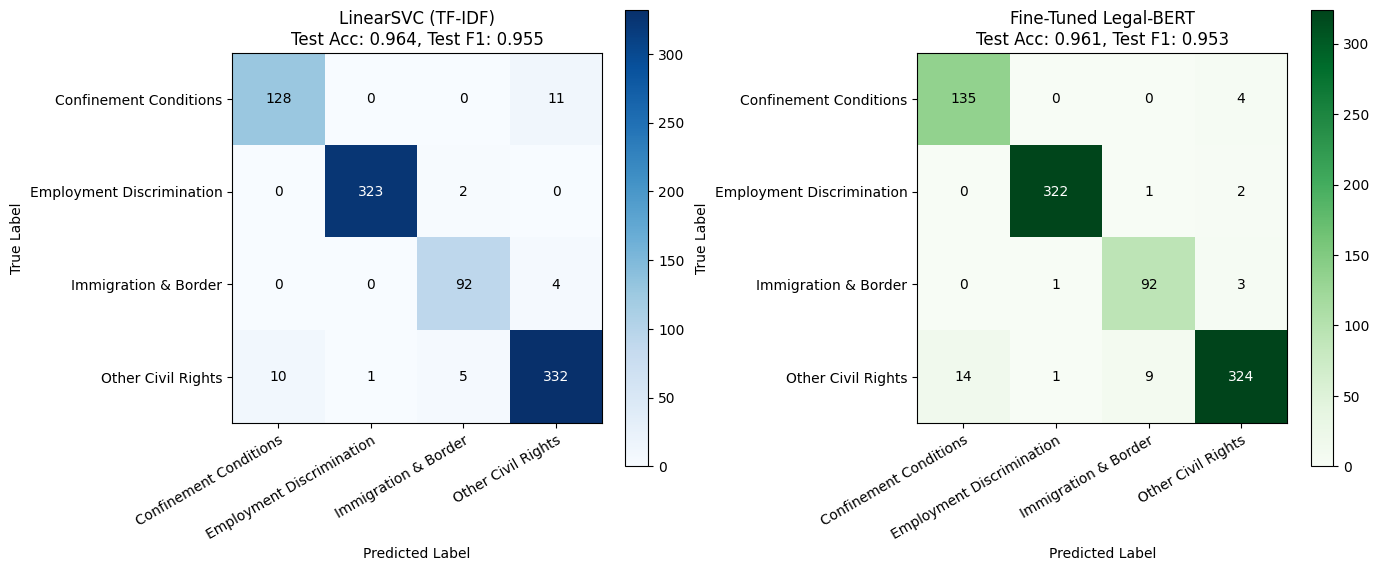

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
classes = best_tfidf_model.classes_

# Confusion Matrix TF-IDF
cm_tfidf = confusion_matrix(y_test, y_test_pred_tfidf, labels=classes)
im1 = axes[0].imshow(cm_tfidf, interpolation='nearest', cmap=plt.cm.Blues)
fig.colorbar(im1, ax=axes[0])
axes[0].set(
    xticks=np.arange(cm_tfidf.shape[1]),
    yticks=np.arange(cm_tfidf.shape[0]),
    xticklabels=classes, 
    yticklabels=classes,
    title=f"{best_tfidf_name}\nTest Acc: {tfidf_test_acc:.3f}, Test F1: {tfidf_test_f1:.3f}",
    ylabel="True Label",
    xlabel="Predicted Label"
)
plt.setp(axes[0].get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")

# Confusion Matrix Legal-BERT
cm_ft = confusion_matrix(y_test, y_test_pred_ft, labels=classes)
im2 = axes[1].imshow(cm_ft, interpolation='nearest', cmap=plt.cm.Greens)
fig.colorbar(im2, ax=axes[1])
axes[1].set(
    xticks=np.arange(cm_ft.shape[1]),
    yticks=np.arange(cm_ft.shape[0]),
    xticklabels=classes, 
    yticklabels=classes,
    title=f"Fine-Tuned Legal-BERT\nTest Acc: {ft_test_acc:.3f}, Test F1: {ft_test_f1:.3f}",
    ylabel="True Label",
    xlabel="Predicted Label"
)
plt.setp(axes[1].get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")

# Add numbers to cells
fmt = 'd'
for ax, cm in zip(axes, [cm_tfidf, cm_ft]):
    thresh = cm.max() / 2.
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], fmt),
                    ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black")

fig.tight_layout()
plt.show()

## 9. Model Interpretability - Top Keywords per Class

To understand what the TF-IDF classifier has learned, we extract the top 12 TF-IDF words mapped to positive weights.

In [16]:
# Load TF-IDF SVC model
tfidf_svc_model = tfidf_models["LinearSVC (TF-IDF)"]

feature_names = np.array(vectorizer.get_feature_names_out())
for i, class_name in enumerate(tfidf_svc_model.classes_):
    coefficients = tfidf_svc_model.coef_[i]
    top_coefficients_indices = np.argsort(coefficients)[-12:][::-1]
    top_terms = feature_names[top_coefficients_indices]
    top_scores = coefficients[top_coefficients_indices]
    
    print(f"\nTop 12 predictive TF-IDF keywords for class '{class_name}':")
    for term, score in zip(top_terms, top_scores):
        print(f"  {term:<25} (weight: {score:.4f})")


Top 12 predictive TF-IDF keywords for class 'Confinement Conditions':
  inmates                   (weight: 2.7516)
  prisoners                 (weight: 2.6854)
  prison                    (weight: 2.4533)
  jail                      (weight: 2.2212)
  corrections               (weight: 1.5864)
  correctional              (weight: 1.5681)
  prisoner                  (weight: 1.4533)
  department corrections    (weight: 1.3795)
  doc                       (weight: 1.2011)
  inmate                    (weight: 1.1636)
  eighth                    (weight: 1.1295)
  county jail               (weight: 1.0156)

Top 12 predictive TF-IDF keywords for class 'Employment Discrimination':
  eeoc                      (weight: 2.1134)
  employees                 (weight: 1.7723)
  title vii                 (weight: 1.5145)
  vii                       (weight: 1.5044)
  employment                (weight: 1.4348)
  employee                  (weight: 1.1980)
  discrimination            (weight: 1.1039)


## 10. Save the Final Models

We package and save the fitted **TF-IDF Vectorizer** and the **LinearSVC classifier** together into a single pickle pipeline file.

In [17]:
os.makedirs('models', exist_ok=True)
pipeline_path = 'models/best_model_pipeline.pkl'

pipeline_data = {
    'vectorizer': vectorizer,
    'model': tfidf_svc_model
}

with open(pipeline_path, 'wb') as f:
    pickle.dump(pipeline_data, f)
print(f"LinearSVC + TF-IDF pipeline saved to: {pipeline_path}")

LinearSVC + TF-IDF pipeline saved to: models/best_model_pipeline.pkl
